In [47]:
import zipfile
import matplotlib.pyplot as plt

In [48]:
path = zipfile.ZipFile("/content/Car Damage Detection.v4i.yolov11.zip")

In [49]:
path.extractall("car_Damage_Detection")

In [50]:
pip install ultralytics

In [51]:
from ultralytics import YOLO

In [52]:
model = YOLO("yolo11n.pt")

In [53]:
model.train(data="/content/car_Damage_Detection/data.yaml",epochs=10,batch=32)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/car_Damage_Detection/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=Fa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a2370f8f9d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

In [54]:
metrics = model.val(data="/content/car_Damage_Detection/data.yaml",plots=True)



Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,517 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 245.9±157.7 MB/s, size: 7.9 KB)
val: Scanning /content/car_Damage_Detection/valid/labels.cache... 836 images, 4 backgrounds, 14 corrupt: 100% ━━━━━━━━━━━━ 836/836 233.8Mit/s 0.0s
val: /content/car_Damage_Detection/valid/images/0007_JPEG.rf.13bb1bd1487a14d00809aae4b66fcbb8.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/car_Damage_Detection/valid/images/damage_5649_jpg.rf.531d8f0350cf37d9a699001860e35e6d.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/car_Damage_Detection/valid/images/damage_6022_jpg.rf.8869d69f4b1152219961607a9cfa1608.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/car_Damage_Detection/valid/images/damage_749_jpg.rf.ddb933596905968892c413bf5

In [55]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Precision: 0.5874668321291441
Recall: 0.5106051200248818
mAP50: 0.5268585499324903
mAP50-95: 0.27121150637533464


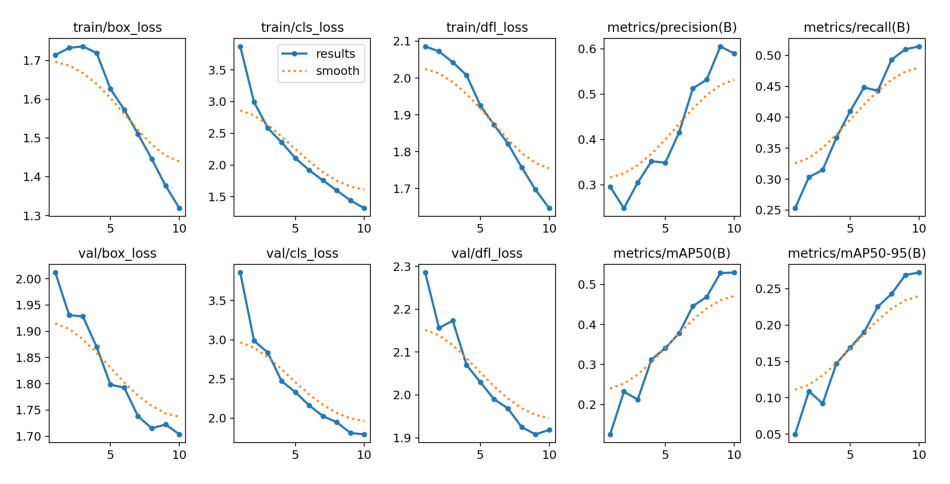

In [56]:
from PIL import Image

image = Image.open("runs/detect/train/results.png")

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

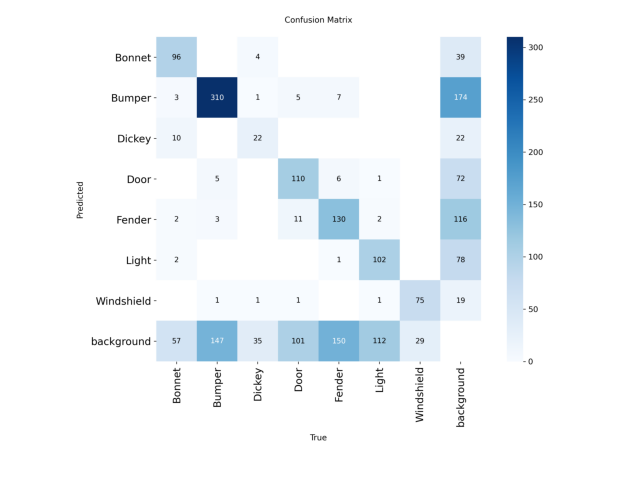

In [57]:
image = Image.open("runs/detect/train/confusion_matrix.png")

plt.figure(figsize=(8, 7))
plt.imshow(image)
plt.axis("off")
plt.show()

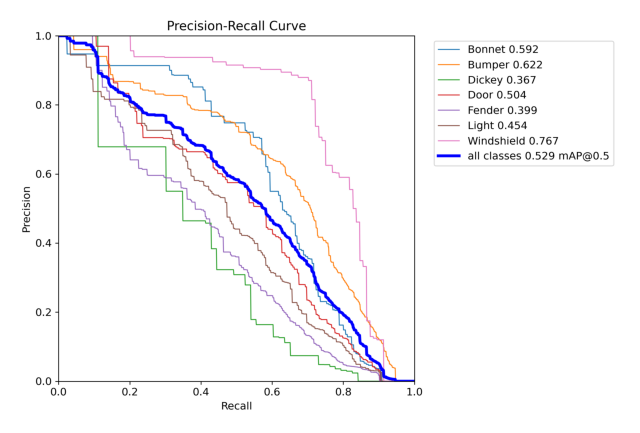

In [59]:
from PIL import Image

image = Image.open("runs/detect/train/BoxPR_curve.png")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()


image 1/1 /content/car_Damage_Detection/train/images/0001_JPEG.rf.e8076299da681eff80d176c8b40afd5e.jpg: 480x640 1 Bonnet, 1 Door, 1 Fender, 9.3ms
Speed: 1.8ms preprocess, 9.3ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)


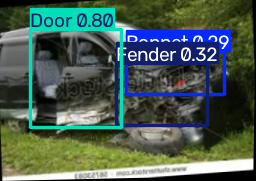

In [60]:
result = model.predict("/content/car_Damage_Detection/train/images/0001_JPEG.rf.e8076299da681eff80d176c8b40afd5e.jpg")
result[0].show()

In [61]:
model.predict("/content/12676974-hd_1920_1080_25fps.mp4",save=True)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/133) /content/12676974-hd_1920_1080_25fps.mp4: 384x640 1 Bumper, 14.7ms
video 1/1 (frame 2/133) /content/12676974-hd_1920_1080_25fps.mp4: 384x640 1 Bumper, 1 Door, 16.0ms
video 1/1 (frame 3/133) /content/12676974-hd_1920_1080_25fps.mp4: 384x640 1 Bumper, 1 Door, 12.6ms
video 1/1 (frame 4/133) /content/12676974-hd_1920_1080_25fps.mp4: 384x640 1 Bumper, 1 Door, 14.7ms
video 1/1 (frame 5/133) /content/12676974-hd_1920_1080_25fps.mp4: 384x6

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'Bonnet', 1: 'Bumper', 2: 'Dickey', 3: 'Door', 4: 'Fender', 5: 'Light', 6: 'Windshield'}
 obb: None
 orig_img: array([[[ 94,  86,  89],
         [ 92,  84,  87],
         [ 87,  79,  82],
         ...,
         [ 73, 114,  92],
         [ 66, 109,  87],
         [ 64, 107,  85]],
 
        [[ 94,  86,  89],
         [ 92,  84,  87],
         [ 88,  80,  83],
         ...,
         [ 73, 114,  92],
         [ 66, 109,  87],
         [ 62, 105,  83]],
 
        [[ 93,  85,  88],
         [ 92,  84,  87],
         [ 89,  81,  84],
         ...,
         [ 64, 105,  83],
         [ 59, 102,  80],
         [ 57, 100,  78]],
 
        ...,
 
        [[ 30,  31,  38],
         [ 31,  32,  39],
         [ 33,  34,  41],
         ...,
         [114, 115, 120],
         [113, 114, 119],
         [113, 114, 119]],
 
        [[ 30,  31

In [63]:
import gradio as gr
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")

def predict(image):
    result = model.predict(image, conf=0.3)
    return result[0].plot()

app = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="numpy", label="🚗 Upload Car Image"),
    outputs=gr.Image(label="🔍 Detection Result"),
    title="🚘 Car Damage Detection",
    description="Upload a car image to detect damaged parts.",
    theme=gr.themes.Soft()
)

app.launch()

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a3e52ba6f1fe30cc92.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
